<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


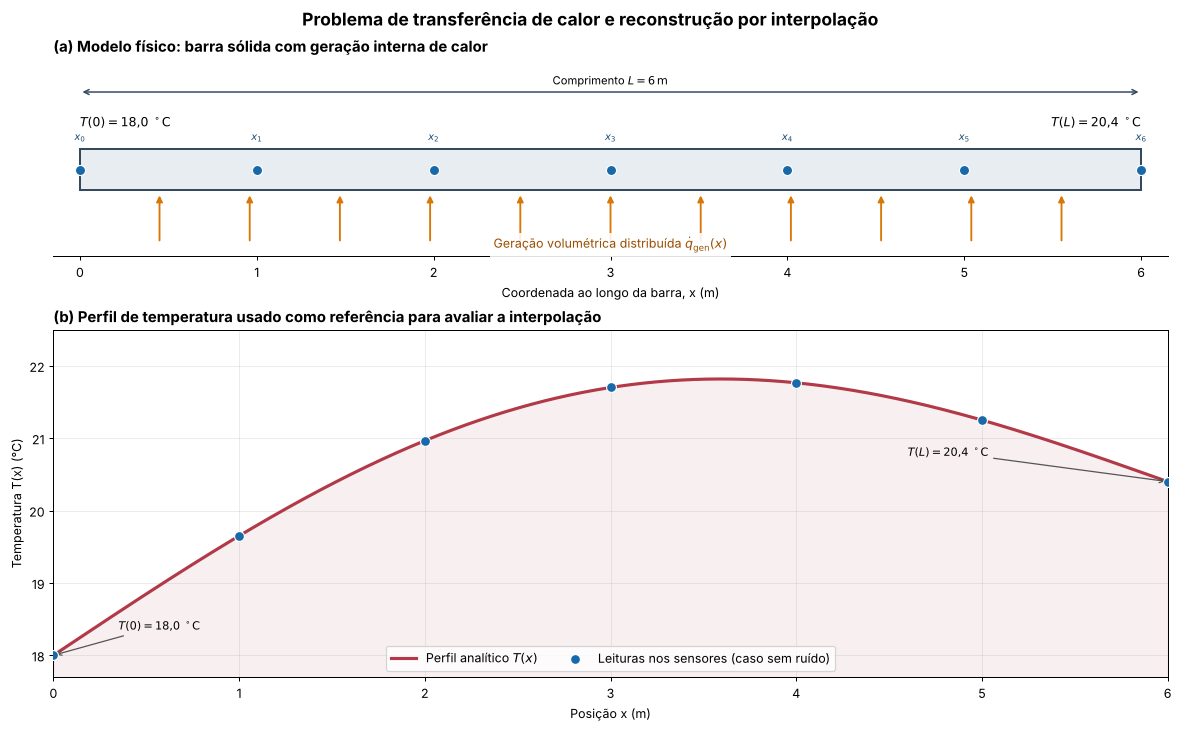

In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


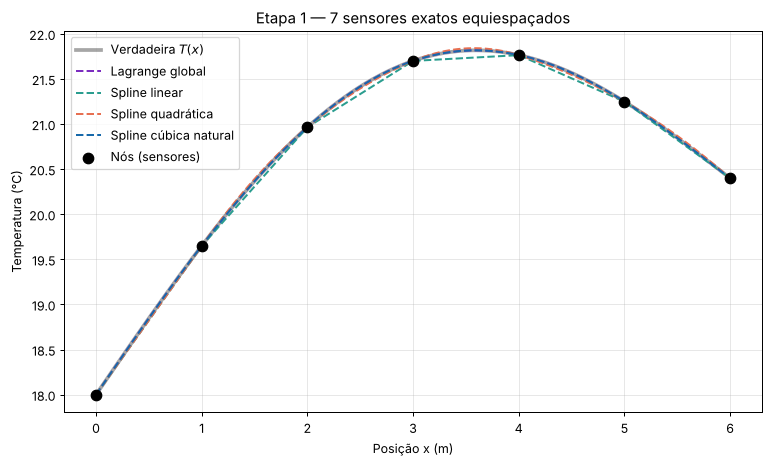

In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Métricas na malha fina (pontos entre os nós)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# Temperaturas: quatro métodos x função verdadeira
cores = {"Lagrange global": "#7b2cbf", "Spline linear": "#2a9d8f",
         "Spline quadrática": "#e76f51", "Spline cúbica natural": "#1769aa"}
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x_fino, T_fino, "k-", lw=3, alpha=0.35, label="Verdadeira $T(x)$")
for nome, m in metodos_7.items():
    ax.plot(x_fino, m(x_fino), "--", lw=1.6, color=cores[nome], label=nome)
ax.scatter(x_nos_7, y_nos_7, s=70, c="k", zorder=5, label="Nós (sensores)")
ax.set_xlabel("Posição x (m)"); ax.set_ylabel("Temperatura (°C)")
ax.set_title("Etapa 1 — 7 sensores exatos equiespaçados")
ax.legend(); ax.grid(alpha=0.3); plt.show()

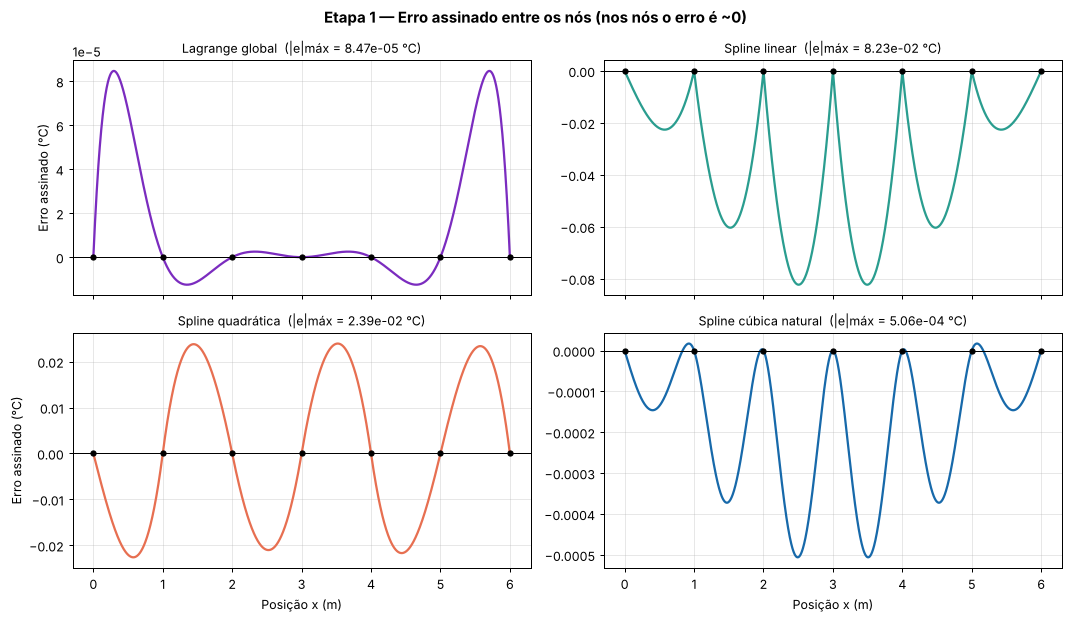

In [ ]:
# Erros assinados e(x) = p(x) - T(x), um painel por método
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (nome, m) in zip(axs.ravel(), metodos_7.items()):
    erro = m(x_fino) - T_fino
    ax.plot(x_fino, erro, color=cores[nome], lw=1.8)
    ax.axhline(0, color="k", lw=0.8)
    ax.plot(x_nos_7, np.zeros_like(x_nos_7), "ko", ms=4)
    ax.set_title(f"{nome}  (|e|máx = {np.max(np.abs(erro)):.2e} °C)", fontsize=10)
    ax.grid(alpha=0.3)
for ax in axs[1]: ax.set_xlabel("Posição x (m)")
for ax in axs[:, 0]: ax.set_ylabel("Erro assinado (°C)")
fig.suptitle("Etapa 1 — Erro assinado entre os nós (nos nós o erro é ~0)", weight="bold")
plt.tight_layout(); plt.show()

### Análise da Etapa 1 (dados exatos, 7 sensores equiespaçados)

| Método | Erro máx. (°C) | RMSE (°C) |
|---|---|---|
| Lagrange global | 8,5·10⁻⁵ | 3,3·10⁻⁵ |
| Spline cúbica natural | 5,1·10⁻⁴ | 2,4·10⁻⁴ |
| Spline quadrática | 2,4·10⁻² | 1,6·10⁻² |
| Spline linear | 8,2·10⁻² | 4,4·10⁻² |

- Com dados **exatos** e perfil **suave** (linear + um seno), o polinômio global de Lagrange foi o melhor: o seno é analítico e é muito bem aproximado por um polinômio de grau 6. A spline cúbica vem em seguida (erro da ordem de $h^4$), depois a quadrática e a linear (ordem $h^2$).
- Os gráficos de erro assinado mostram erro ≈ 0 nos nós e **abaulamento entre eles**. A spline linear subestima a temperatura na região central, onde o perfil é côncavo (a corda fica abaixo da curva), com erro de sinal fixo; Lagrange e spline cúbica oscilam com amplitude muito menor.
- Observação: a spline quadrática depende da condição arbitrária $c_0=0$ no primeiro intervalo; ela propaga esse erro ao longo da barra e fica pior que a cúbica.

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

Razão Emax(equi)/Emax(Cheb):
N
5    1.950e+00
9    4.810e+00
13   1.630e+01
17   1.400e+02


,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçado,4.530257e-03,2.159567e-03
1,5,Chebyshev-Lobatto,2.326599e-03,1.532697e-03
2,9,Equiespaçado,1.043537e-06,3.438146e-07
3,9,Chebyshev-Lobatto,2.167582e-07,1.202332e-07
4,13,Equiespaçado,5.911716e-11,1.545530e-11
5,13,Chebyshev-Lobatto,3.627321e-12,1.932013e-12
6,17,Equiespaçado,1.989520e-12,2.445428e-13
7,17,Chebyshev-Lobatto,1.421085e-14,3.807252e-15


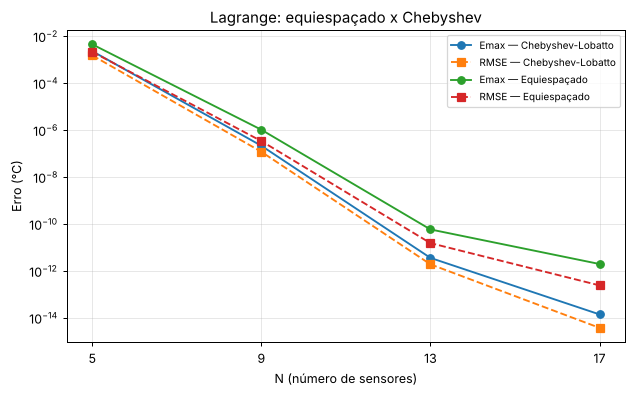

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

linhas = []
for N in (5, 9, 13, 17):
    for nome, xs in (("Equiespaçado", np.linspace(x_min, x_max, N)),
                     ("Chebyshev-Lobatto", nos_chebyshev_lobatto(x_min, x_max, N))):
        p = BarycentricInterpolator(xs, temperatura_real(xs))
        e = p(x_fino) - T_fino
        linhas.append({"N": N, "Distribuição": nome,
                       "Erro máximo (°C)": np.max(np.abs(e)),
                       "RMSE (°C)": np.sqrt(np.mean(e**2))})
tabela_nos = pd.DataFrame(linhas)
pd.options.display.float_format = "{:.3e}".format
display(tabela_nos)

# Razão equiespaçado / Chebyshev
piv = tabela_nos.pivot(index="N", columns="Distribuição", values="Erro máximo (°C)")
print("Razão Emax(equi)/Emax(Cheb):")
print((piv["Equiespaçado"]/piv["Chebyshev-Lobatto"]).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, g in tabela_nos.groupby("Distribuição"):
    ax.semilogy(g["N"], g["Erro máximo (°C)"], "o-", label=f"Emax — {nome}")
    ax.semilogy(g["N"], g["RMSE (°C)"], "s--", label=f"RMSE — {nome}")
ax.set_xlabel("N (número de sensores)"); ax.set_ylabel("Erro (°C)")
ax.set_xticks([5, 9, 13, 17]); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Lagrange: equiespaçado x Chebyshev"); plt.show()
pd.options.display.float_format = None

### Análise da Etapa 2 (nós equiespaçados × Chebyshev-Lobatto, Lagrange)

| N | Emax equi. | Emax Cheb. | razão |
|---|---|---|---|
| 5 | 4,5·10⁻³ | 2,3·10⁻³ | 2 |
| 9 | 1,0·10⁻⁶ | 2,2·10⁻⁷ | ≈ 5 |
| 13 | 5,9·10⁻¹¹ | 3,6·10⁻¹² | ≈ 16 |
| 17 | 2,0·10⁻¹² | 1,4·10⁻¹⁴ | ≈ 140 |

- Chebyshev foi melhor em todos os N, e a vantagem **cresce** com N. Nos nós equiespaçados, o produto $\prod (x-x_i)$ do termo de erro é muito maior perto das extremidades; Chebyshev equilibra essa amplitude.
- **Cautela:** aqui não apareceu o fenômeno de Runge (erro *crescendo* com N) porque o perfil $T(x)$ é **inteira/analítica** (seno + reta), com derivadas de ordem alta pequenas ($\sim (\pi/L)^n$), que são "domadas" por $1/n!$. Para funções com singularidades próximas ao intervalo (ex.: $1/(1+25x^2)$), a diferença seria dramática. A redução observada vale para **este** perfil, não é uma prova geral.
- Em N=17 o erro já está perto do ruído de arredondamento da máquina (~10⁻¹⁴ a 10⁻¹²).

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

Melhor método por Emax:
 N                Método     Emax
 4 Spline cúbica natural 1.02e-02
 5    Lagrange Chebyshev 2.33e-03
 6 Spline cúbica natural 1.12e-03
 7    Lagrange Chebyshev 3.35e-05
 8    Lagrange Chebyshev 3.38e-05
 9    Lagrange Chebyshev 2.17e-07
10    Lagrange Chebyshev 2.34e-07
11    Lagrange Chebyshev 1.10e-09
12    Lagrange Chebyshev 1.10e-09
13    Lagrange Chebyshev 3.62e-12
14    Lagrange Chebyshev 3.76e-12
15    Lagrange Chebyshev 2.13e-14
16    Lagrange Chebyshev 1.78e-14
17    Lagrange Chebyshev 1.07e-14
18    Lagrange Chebyshev 1.42e-14
19    Lagrange Chebyshev 1.42e-14
20    Lagrange Chebyshev 1.42e-14
21    Lagrange Chebyshev 1.42e-14
22    Lagrange Chebyshev 1.42e-14
23    Lagrange Chebyshev 1.78e-14
24    Lagrange Chebyshev 1.42e-14
25    Lagrange Chebyshev 1.42e-14
26    Lagrange Chebyshev 1.42e-14
27    Lagrange Chebyshev 1.42e-14
28    Lagrange Chebyshev 1.42e-14
29    Lagrange Chebyshev 1.78e-14
30    Lagrange Chebyshev 1.42e-14
31    Lagrange Chebyshev

Emax                                                           RMSE                                            
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural
N                                                                                                                                   
4            1.429774e-01          1.090393e-01          1.017696e-02       8.094463e-02          6.829596e-02          4.786615e-03
6            3.017232e-03          3.282437e-03          1.118143e-03       1.725242e-03          1.511994e-03          5.133331e-04
8            3.375574e-05          6.095488e-05          2.776530e-04       1.937399e-05          2.251049e-05          1.263832e-04
10           2.337620e-07          7.516743e-07          9.963236e-05       1.344155e-07          2.375289e-07          4.517820e-05
12           1.100478e-09          6.565600e-09          4.420418e-05       6.334608e-10          1.840224e-09          2.000419e-05
16           1.776357e-14          1.811884e-12          1.266476e-05       6.315362e-15          1.618361e-13          5.720312e-06
20           1.421085e-14          1.557865e-11          4.899580e-06       4.129141e-15          1.349121e-12          2.211105e-06
30           1.421085e-14          1.160711e-08          8.992694e-07       4.673722e-15          7.905357e-10          4.054948e-07
40           1.776357e-14          9.831159e-06          2.745707e-07       4.316601e-15          5.972312e-07          1.237740e-07

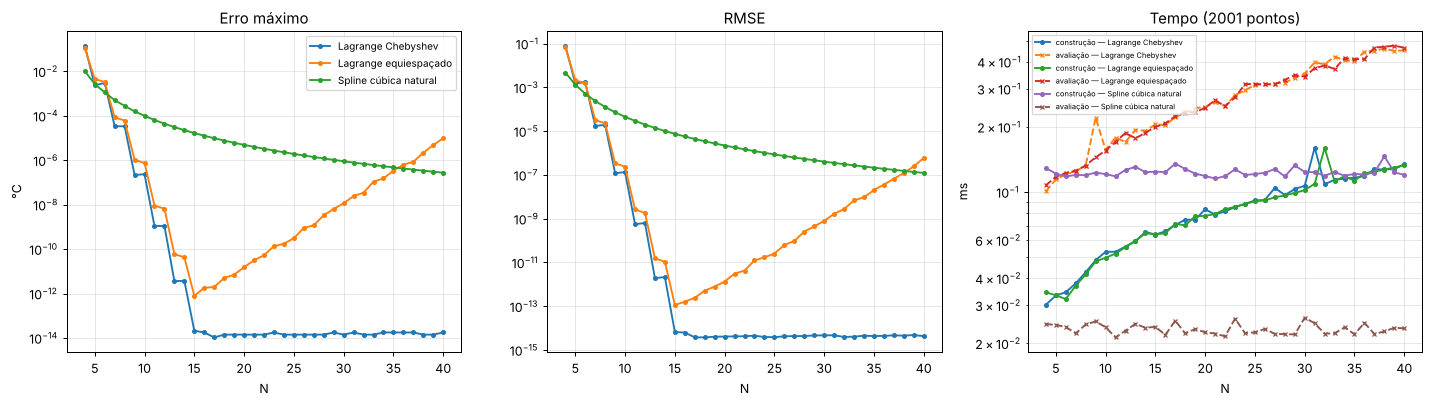

In [ ]:
import time

def medir(fn, rep=5):
    """Menor tempo (s) de rep execuções."""
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); r = fn(); ts.append(time.perf_counter()-t0)
    return min(ts), r

registros = []
for N in range(4, 41):
    xe = np.linspace(x_min, x_max, N)
    xc = nos_chebyshev_lobatto(x_min, x_max, N)
    for nome, xs, ctor in (
        ("Lagrange equiespaçado", xe, lambda x, y: BarycentricInterpolator(x, y)),
        ("Lagrange Chebyshev",    xc, lambda x, y: BarycentricInterpolator(x, y)),
        ("Spline cúbica natural", xe, lambda x, y: CubicSpline(x, y, bc_type="natural"))):
        ys = temperatura_real(xs)
        t_c, p = medir(lambda: ctor(xs, ys))
        t_a, yp = medir(lambda: p(x_fino))
        e = yp - T_fino
        registros.append({"N": N, "Método": nome,
                          "Emax": np.max(np.abs(e)),
                          "RMSE": np.sqrt(np.mean(e**2)),
                          "t_construção (ms)": 1e3*t_c,
                          "t_avaliação (ms)": 1e3*t_a})
df3 = pd.DataFrame(registros)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for nome, g in df3.groupby("Método"):
    axs[0].semilogy(g["N"], g["Emax"], "o-", ms=3, label=nome)
    axs[1].semilogy(g["N"], g["RMSE"], "o-", ms=3, label=nome)
    axs[2].semilogy(g["N"], g["t_construção (ms)"], "o-", ms=3, label=f"construção — {nome}")
    axs[2].semilogy(g["N"], g["t_avaliação (ms)"], "x--", ms=3, label=f"avaliação — {nome}")
axs[0].set_title("Erro máximo"); axs[1].set_title("RMSE"); axs[2].set_title("Tempo (2001 pontos)")
for ax in axs: ax.set_xlabel("N"); ax.grid(alpha=0.3, which="both")
axs[0].set_ylabel("°C"); axs[2].set_ylabel("ms"); axs[0].legend(fontsize=8); axs[2].legend(fontsize=6)
plt.tight_layout(); plt.show()

pd.options.display.float_format = "{:.2e}".format
sel = df3[df3["N"].isin([4, 6, 8, 10, 12, 16, 20, 30, 40])]
display(sel.pivot(index="N", columns="Método", values=["Emax", "RMSE"]))
# Melhor método (por Emax) em cada N
melhor = df3.loc[df3.groupby("N")["Emax"].idxmin(), ["N", "Método", "Emax"]]
print("Melhor método por Emax:")
print(melhor.to_string(index=False))
pd.options.display.float_format = None

### Análise da Etapa 3 (N de 4 a 40, erro e custo)

Resultados (Emax, °C):

| N | Lagrange equi. | Lagrange Cheb. | Spline cúbica |
|---|---|---|---|
| 4 | 1,1·10⁻¹ | 1,4·10⁻¹ | **1,0·10⁻²** |
| 6 | 3,3·10⁻³ | 3,0·10⁻³ | **1,1·10⁻³** |
| 8 | 6,1·10⁻⁵ | **3,4·10⁻⁵** | 2,8·10⁻⁴ |
| 12 | 6,6·10⁻⁹ | **1,1·10⁻⁹** | 4,4·10⁻⁵ |
| 20 | 1,6·10⁻¹¹ | **1,4·10⁻¹⁴** | 4,9·10⁻⁶ |
| 40 | 9,8·10⁻⁶ | **1,8·10⁻¹⁴** | 2,7·10⁻⁷ |

- **Não há um único método superior para todo N.** Com poucos nós (N = 4 e 6) a spline cúbica vence (o polinômio de grau 3 ou 5 ainda é pobre). A partir de N ≈ 7–8, Lagrange (Chebyshev) vence por várias ordens de grandeza, com convergência geométrica até o piso de arredondamento (~10⁻¹⁴). A spline cúbica converge algebricamente (~$N^{-4}$, inclinação visível no gráfico log).
- **Estabilidade numérica:** Lagrange equiespaçado **piora** para N grande (de ~10⁻¹¹ em N≈20 para ~10⁻⁵ em N=40): a constante de Lebesgue cresce exponencialmente e os erros de arredondamento são amplificados, mesmo com a forma baricêntrica. Chebyshev tem constante de Lebesgue ~ $\log N$ e fica estável. A spline cúbica é estável para qualquer N (sistema tridiagonal bem condicionado).
- **Custo:** a construção da forma baricêntrica é $O(N^2)$ e a avaliação $O(N)$ por ponto; a spline cúbica é $O(N)$ para construir (sistema tridiagonal) e $O(\log N)$ por avaliação (busca do intervalo). Para N ≤ 40 e 2001 pontos todos os tempos são de milissegundos, então o custo **não** é o fator decisivo aqui; o é a estabilidade. Os tempos absolutos dependem da máquina (veja o gráfico).

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

Extrapolação (Lagrange (N=8)): erro em x=6 m = 0.006 °C; Emax em [4.5, 6] = 0.006 °C
Extrapolação (Spline cúbica natural): erro em x=6 m = 1.176 °C; Emax em [4.5, 6] = 1.176 °C
Para comparar, spline cúbica DENTRO de [0, 4.5]: Emax = 0.0100 °C


Emax médio (°C)                                                RMSE médio (°C)                                            
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural
N                                                                                                                                   
5                   0.170                 0.179                 0.159              0.092                 0.097                 0.085
7                   0.182                 0.259                 0.182              0.091                 0.120                 0.091
9                   0.196                 0.479                 0.189              0.095                 0.169                 0.089
13                  0.218                 3.344                 0.214              0.097                 0.795                 0.093
17                  0.231                31.625                 0.219              0.099                 6.314                 0.091
25                  0.248              4063.972                 0.237              0.099               648.330                 0.093

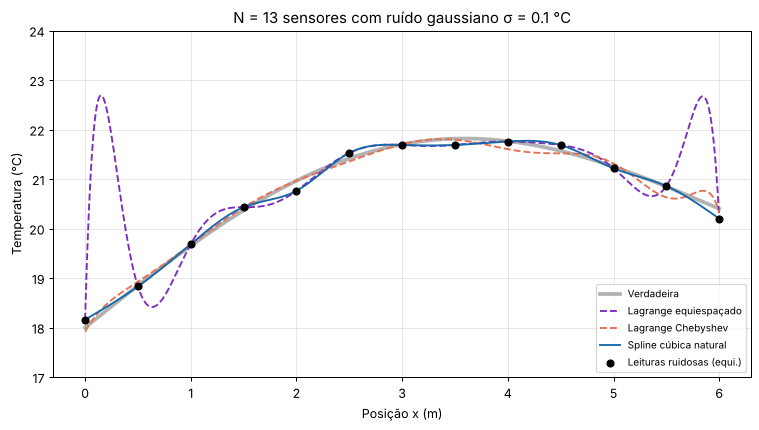

In [ ]:
# Sensores ruidosos: ruído gaussiano sigma, Monte Carlo com 300 realizações.
rng = np.random.default_rng(42)
sigma = 0.10  # °C
n_mc = 300

def run_ruido(N, sigma, n_mc=n_mc):
    xe = np.linspace(x_min, x_max, N); xc = nos_chebyshev_lobatto(x_min, x_max, N)
    cfg = {"Lagrange equiespaçado": (xe, BarycentricInterpolator),
           "Lagrange Chebyshev": (xc, BarycentricInterpolator),
           "Spline cúbica natural": (xe, lambda a, b: CubicSpline(a, b, bc_type="natural"))}
    res = {}
    for nome, (xs, ctor) in cfg.items():
        y0 = temperatura_real(xs); emax = []; rmse = []
        for _ in range(n_mc):
            e = ctor(xs, y0 + rng.normal(0, sigma, len(xs)))(x_fino) - T_fino
            emax.append(np.max(np.abs(e))); rmse.append(np.sqrt(np.mean(e**2)))
        res[nome] = (np.mean(emax), np.mean(rmse))
    return res

linhas = []
for N in (5, 7, 9, 13, 17, 25):
    for nome, (em, rm) in run_ruido(N, sigma).items():
        linhas.append({"N": N, "Método": nome, "Emax médio (°C)": em, "RMSE médio (°C)": rm})
df_ruido = pd.DataFrame(linhas)
display(df_ruido.pivot(index="N", columns="Método", values=["Emax médio (°C)", "RMSE médio (°C)"]).round(3))

# Uma realização com N=13 para visualização
N = 13
xe = np.linspace(x_min, x_max, N); xc = nos_chebyshev_lobatto(x_min, x_max, N)
y_e = temperatura_real(xe) + rng.normal(0, sigma, N)
y_c = temperatura_real(xc) + rng.normal(0, sigma, N)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_fino, T_fino, "k-", lw=3, alpha=0.3, label="Verdadeira")
ax.plot(x_fino, BarycentricInterpolator(xe, y_e)(x_fino), "--", color="#7b2cbf", label="Lagrange equiespaçado")
ax.plot(x_fino, BarycentricInterpolator(xc, y_c)(x_fino), "--", color="#e76f51", label="Lagrange Chebyshev")
ax.plot(x_fino, CubicSpline(xe, y_e, bc_type="natural")(x_fino), "-", color="#1769aa", label="Spline cúbica natural")
ax.scatter(xe, y_e, c="k", s=30, zorder=5, label="Leituras ruidosas (equi.)")
ax.set_ylim(17, 24); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_xlabel("Posição x (m)"); ax.set_ylabel("Temperatura (°C)")
ax.set_title(f"N = {N} sensores com ruído gaussiano σ = {sigma} °C"); plt.show()

# Extrapolação: nós em [0, 4.5] m, avaliação em [4.5, 6] m
xs = np.linspace(0, 4.5, 8); ys = temperatura_real(xs)
x_ext = np.linspace(4.5, 6, 200)
for nome, p in (("Lagrange (N=8)", BarycentricInterpolator(xs, ys)),
                ("Spline cúbica natural", CubicSpline(xs, ys, bc_type="natural", extrapolate=True))):
    e = np.abs(p(x_ext) - temperatura_real(x_ext))
    print(f"Extrapolação ({nome}): erro em x=6 m = {e[-1]:.3f} °C; Emax em [4.5, 6] = {e.max():.3f} °C")
e_int = np.abs(CubicSpline(xs, ys, bc_type="natural")(np.linspace(0, 4.5, 500)) - temperatura_real(np.linspace(0, 4.5, 500))).max()
print(f"Para comparar, spline cúbica DENTRO de [0, 4.5]: Emax = {e_int:.4f} °C")

### Análise do experimento com ruído (σ = 0,10 °C, 300 realizações Monte Carlo)

RMSE médio (°C) na malha fina:

| N | Lagrange equi. | Lagrange Cheb. | Spline cúbica |
|---|---|---|---|
| 5 | 0,097 | 0,092 | 0,085 |
| 9 | 0,169 | 0,095 | 0,089 |
| 13 | 0,795 | 0,097 | 0,093 |
| 17 | 6,3 | 0,099 | 0,091 |
| 25 | 648 | 0,099 | 0,093 |

- Com ruído, o interpolador **reproduz o ruído nos nós** e o propaga. Lagrange equiespaçado amplifica o ruído de forma catastrófica com N (constante de Lebesgue exponencial): o RMSE chega a centenas de °C. É a pior escolha.
- Spline cúbica e Lagrange-Chebyshev mantêm RMSE ≈ σ (≈ 0,09–0,10 °C): o erro passa a ser dominado pelo ruído, não pela interpolação. **Mais sensores não reduzem o erro além do nível do ruído** quando se interpola; os erros de truncamento (10⁻⁴ a 10⁻¹⁴ °C) ficam muito abaixo de σ e tornam-se irrelevantes.
- Já o erro **máximo** médio (~0,18–0,25 °C, ≈ 2 σ) é maior que o RMSE, como esperado.
- **Extrapolação** (nós em 0–4,5 m, avaliação em 4,5–6 m): a spline cúbica natural errou até 1,18 °C em x = 6 m (a condição $S''=0$ na borda é fisicamente incorreta, já que $T''\neq0$), contra 0,010 °C **dentro** do intervalo medido. Lagrange extrapolou bem aqui (0,006 °C), mas só porque o perfil é analítico e os dados são exatos; com ruído ou outro perfil, extrapolar com polinômio de grau alto é muito instável.

## Recomendação técnica (Etapa 4)

**1. Poucos sensores exatos (N ≈ 4–6):** usar **spline cúbica natural** (ou Lagrange com Chebyshev se for possível escolher as posições e N ≥ 7). Com N = 4 e 6 a spline teve o menor erro (1,0·10⁻² e 1,1·10⁻³ °C de Emax). Spline linear/quadrática só se a simplicidade for prioridade (erros de 10⁻²–10⁻¹ °C).

**2. Aumentando o número de sensores:** com dados exatos e perfil suave, a partir de N ≈ 7–8 o Lagrange com nós de Chebyshev é superior (erro até 10⁻¹⁴ °C), mas **exige** posicionar sensores nas posições de Chebyshev. Com sensores igualmente espaçados, **não usar Lagrange global para N grande** (instável: Emax sobe de ~10⁻¹¹ para ~10⁻⁵ de N=20 para N=40). A spline cúbica é a opção robusta e sem restrição de posição, com erro $\sim N^{-4}$.

**3. Com ruído:** interpolação não filtra ruído; ela o copia e (Lagrange equiespaçado) o amplifica. Recomendo spline cúbica ou Lagrange-Chebyshev com RMSE ≈ σ, e, se σ for relevante frente à precisão desejada, **trocar interpolação por ajuste/suavização** (mínimos quadrados com polinômio de baixo grau, spline de suavização) e/ou medições repetidas (σ/√m). Não adianta aumentar N além do ponto em que o erro de truncamento fica abaixo de σ.

**4. Extremidades:** (a) em Lagrange equiespaçado o erro oscila mais perto das bordas (fenômeno de Runge): preferir nós de Chebyshev (mais sensores nas bordas); (b) na spline cúbica, a condição natural $S''=0$ degrada a precisão perto das bordas se $T''\neq0$ ali: se $T'$ ou $T''$ forem conhecidos, usar condição *clamped*/*not-a-knot*; neste problema as temperaturas das extremidades são conhecidas (Dirichlet) e **devem** ser incluídas como nós; (c) nunca extrapolar além dos sensores extremos.

**5. Limitações quando a verdade é desconhecida:** (i) em campo não se pode calcular $e(x)$; só se estima o erro por validação cruzada (deixar um sensor de fora), comparação entre métodos/refinamentos (diferença entre spline e Lagrange como indicador) e pelas estimativas teóricas, que dependem de derivadas desconhecidas; (ii) os resultados aqui valem para um perfil suave e analítico; com fontes localizadas ou descontinuidades, Lagrange global oscila e splines com nós adequados são preferíveis; (iii) o modelo é idealizado (1D, estacionário, propriedades constantes); (iv) calibração e viés sistemático dos sensores não são capturados por ruído gaussiano; (v) **interpolar** (dentro de [x₀, x_N]) é confiável e controlável; **extrapolar** (fora) tem erro não controlado (spline: 1,18 °C; Lagrange: crescimento polinomial em geral).

**Métricas usadas:** erro máximo e RMSE (e MAE na Etapa 1).